In [1]:
# # # A # # # 
import random
import matplotlib.pyplot as plt
random.seed(725)

In [2]:
# # # B # # # 
class ProbVal:
    def __set_name__(self, owner, name):
        self.private_name = '_' + name

    def __get__(self, obj, objtype=None):
        return getattr(obj, self.private_name)

    def __set__(self, obj, value):
        clipped_value = max(0.0, min(1.0, float(value)))
        setattr(obj, self.private_name, clipped_value)

In [3]:
# # # C # # #
class Creature:
    p_death = ProbVal()
    p_reproduce = ProbVal()
    sigma = 0.05

    def __init__(self, p_death: float, p_reproduce: float):
        self.p_death = p_death
        self.p_reproduce = p_reproduce
        self.alive = True

    def kill(self):
        if random.random() < self.p_death:
            self.alive = False

    def reproduce(self):
        if self.alive and (random.random() < self.p_reproduce):
            return self.__class__(p_death=self.p_death, p_reproduce=self.p_reproduce)
        return None

In [4]:
# # # D # # # 
class Prey(Creature):
    name = "Prey"
    p_hunt = ProbVal()

    def __init__(self, p_death: float, p_reproduce: float, p_hunt: float):
        super().__init__(p_death, p_reproduce)
        self.p_hunt = p_hunt

    def reproduce(self):
        if self.alive and (random.random() < self.p_reproduce):
            return Prey(p_death=self.p_death, p_reproduce=self.p_reproduce, p_hunt=self.p_hunt)
        return None

class Predator(Creature):
    name = "Predator"
    p_death_hungry = 0.9

    def __init__(self, p_death: float, p_reproduce: float):
        super().__init__(p_death, p_reproduce)
        self.hungry = True

    def hunt(self, prey: Prey):
        if random.random() < prey.p_hunt:
            prey.alive = False
            self.hungry = False

    def kill(self):
        death_prob = self.p_death_hungry if self.hungry else self.p_death
        if random.random() < death_prob:
            self.alive = False

In [9]:
# # # E # # # 
class Population:
    def __init__(self, population_data: dict):
        self._instances = set()
        self.history = []
        
        for cls, count in population_data.items():
            for _ in range(count):
                if cls == Prey:
                    self._instances.add(Prey(p_death=0.1, p_reproduce=0.4, p_hunt=0.5))
                elif cls == Predator:
                    self._instances.add(Predator(p_death=0.1, p_reproduce=0.2))
                    
        self.update_counts()

    def update_counts(self):
        counts = {"Prey": 0, "Predator": 0}
        for creature in self._instances:
            if creature.alive:
                counts[creature.name] += 1
        self.n = counts

    def hunting(self):
        predators = [p for p in self._instances if p.name == "Predator" and p.alive]
        preys = [p for p in self._instances if p.name == "Prey" and p.alive]
        
        for p in predators:
            p.hungry = True
            
        random.shuffle(predators)
        random.shuffle(preys)
        
        pairs_count = min(len(predators), len(preys))
        for i in range(pairs_count):
            predators[i].hunt(preys[i])

    def natural_selection(self):
        newborns = []
        for creature in self._instances:
            if creature.alive:
                child = creature.reproduce()
                if child:
                    newborns.append(child)
                    
        self.hunting()
        
        for creature in self._instances:
            if creature.alive:
                creature.kill()
                
        self.update_counts()
        self.history.append(self.n.copy())
        
        self._instances = {c for c in self._instances if c.alive}
        self._instances.update(newborns)


    def plot_history(self):
        prey_counts = [h["Prey"] for h in self.history]
        pred_counts = [h["Predator"] for h in self.history]
        
        plt.figure(figsize=(10, 5))
        plt.plot(prey_counts, label="Prey", color="green")
        plt.plot(pred_counts, label="Predator", color="red")
        plt.title("Trajektoria liczebności gatunków")
        plt.xlabel("Kroki symulacji")
        plt.ylabel("Liczebność")
        plt.legend()
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.show()

    def plot_histogram(self, attr: str):
        values = [getattr(c, attr) for c in self._instances if hasattr(c, attr)]
        if not values:
            return
            
        plt.hist(values, bins=10, edgecolor="black")
        plt.title(f"Histogram atrybutu: {attr}")
        plt.xlabel("Wartość")
        plt.ylabel("Liczba osobników")
        plt.show()

Za dużo ofiar


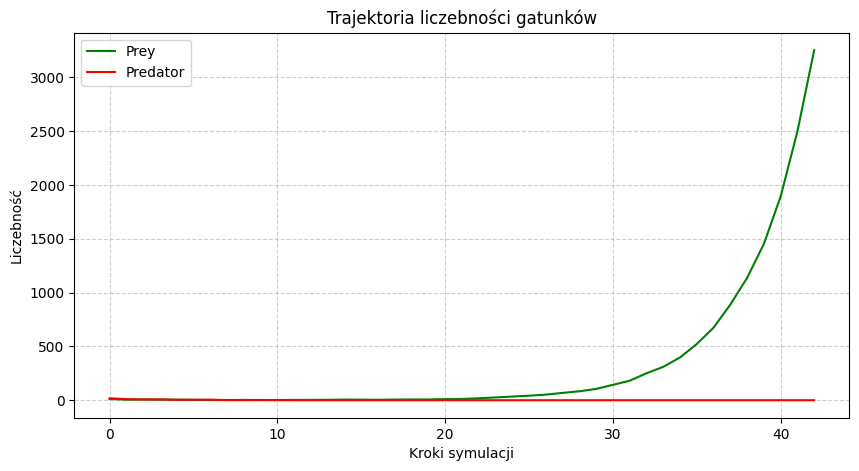

In [10]:
# # # F # # # 
pop = Population({Prey: 30, Predator: 30})

for krok in range(150):
    pop.natural_selection()
    
    liczba_ofiar = pop.n.get("Prey", 0)
    liczba_drapieznikow = pop.n.get("Predator", 0)
    
    if liczba_ofiar > 3000:
        print(f"Za dużo ofiar")
        break
        
    if liczba_ofiar == 0 and liczba_drapieznikow == 0:
        print(f"Wymarcie gatunku")
        break

pop.plot_history()

**WNIOSEK** Drapieżniki wymarły niemal natychmiast, natomiast ofiary zostały pozbawione naturalnego wroga, dlatego zaczęły niekontrolowanie się rozmnażać (wysoki skok zielonej linii na wykresie)